# Modul 9 – Morfologi Citra
**Praktikum Pengolahan Citra dan Visi Komputer**
- **Nama**: Femas Akbar Fathurohim
- **File**: Week9.ipynb
- **Topik**: Operasi Morfologi (Dilasi, Erosi, Opening, Closing, Top-Hat, Black-Hat, Skeleton, Thinning, dan Perbaikan Citra KTP)


In [1]:
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    pass

def get_image_path(filename):
    candidates = [
        os.path.join('/content/drive/MyDrive/PCVK/Images', filename),
        os.path.join('/content/drive/MyDrive/Images', filename),
        os.path.join('images', filename),
        os.path.join('/content/PCVK_Ganjil_2026/images', filename),
        os.path.join('/content', filename),
        filename
    ]
    for path in candidates:
        if os.path.exists(path):
            return path
    return os.path.join('images', filename)


Mounted at /content/drive


In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from skimage import filters, morphology, io, color, img_as_float


### 3. Dilasi Citra Tanpa Library (Structuring Element Cross 3x3)


In [4]:
def dilasi_citra(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

img_d = cv2.imread(get_image_path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()


AttributeError: 'NoneType' object has no attribute 'shape'

### 4. Dilasi Citra Menggunakan Library OpenCV


[[1 1 1]
 [1 1 1]
 [1 1 1]]


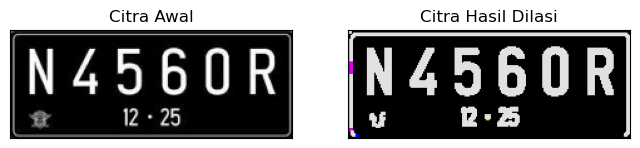

In [ ]:
img = cv2.imread(get_image_path('plat nomer.jpg'))
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
dilasi = cv2.dilate(thresh, kernel, iterations=1)
print(kernel)

plt.figure(figsize=(8, 4))
plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(dilasi), plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()


### 5. Erosi Citra Tanpa Library (Structuring Element Square 5x5)


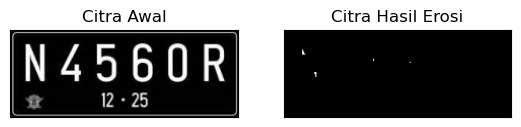

In [ ]:
def erosi_citra(F, k):
    m, n = F.shape
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

img_e = cv2.imread(get_image_path('plat nomer.jpg'), 0)
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1, k)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()


### 6. Erosi Citra Menggunakan Library OpenCV (Square 5x5)


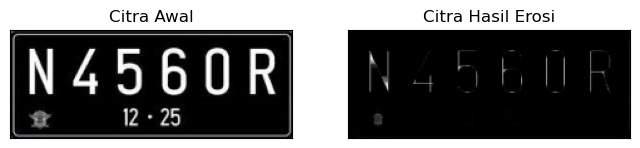

In [ ]:
img = cv2.imread(get_image_path('plat nomer.jpg'))
kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)

plt.figure(figsize=(8, 4))
plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(erosion), plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()


### 7. Operasi Opening Tanpa dan Dengan Library OpenCV


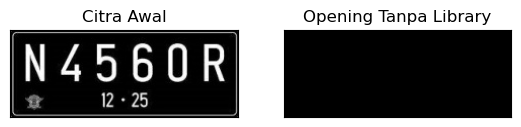

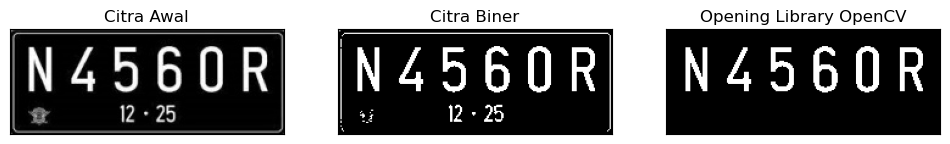

In [ ]:
img_o = cv2.imread(get_image_path('plat nomer.jpg'), 0)
reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
k = 7
imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgO, cmap='gray')
plt.title('Opening Tanpa Library'), plt.xticks([]), plt.yticks([])
plt.show()

img = cv2.imread(get_image_path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(openn, cmap='gray')
plt.title('Opening Library OpenCV'), plt.xticks([]), plt.yticks([])
plt.show()


### 8. Operasi Closing Tanpa dan Dengan Library OpenCV


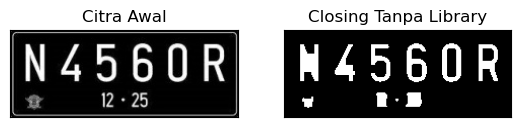

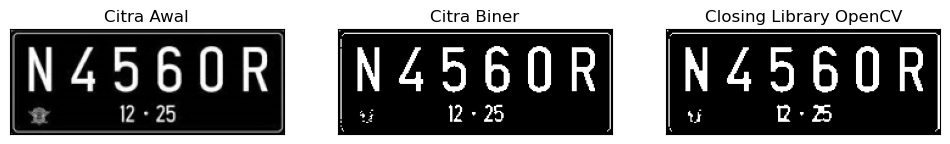

In [ ]:
img_c = cv2.imread(get_image_path('plat nomer.jpg'), 0)
retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
k = 7
imgC = erosi_citra(dilasi_citra(threshc, k), k)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgC, cmap='gray')
plt.title('Closing Tanpa Library'), plt.xticks([]), plt.yticks([])
plt.show()

img = cv2.imread(get_image_path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(closs, cmap='gray')
plt.title('Closing Library OpenCV'), plt.xticks([]), plt.yticks([])
plt.show()


### 9. Dilasi Structuring Element Cross 3x3 dan 5x5


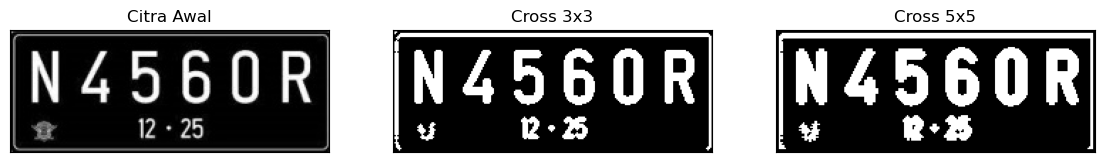

In [ ]:
def dilasi_cross_3(F):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype=np.uint8)
    w = 3
    constant1 = (w - 1) // 2

    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

def dilasi_cross_5(F):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = np.array([[0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0],
                    [1, 1, 1, 1, 1],
                    [0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0]], dtype=np.uint8)
    w = 5
    constant1 = (w - 1) // 2

    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

img_d = cv2.imread(get_image_path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

imgD_cross3 = dilasi_cross_3(thresh)
imgD_cross5 = dilasi_cross_5(thresh)

plt.figure(figsize=(14, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD_cross3, cmap='gray')
plt.title('Cross 3x3'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(imgD_cross5, cmap='gray')
plt.title('Cross 5x5'), plt.xticks([]), plt.yticks([])
plt.show()


### 10. Dilasi Structuring Element Circular 3x3 dan 5x5


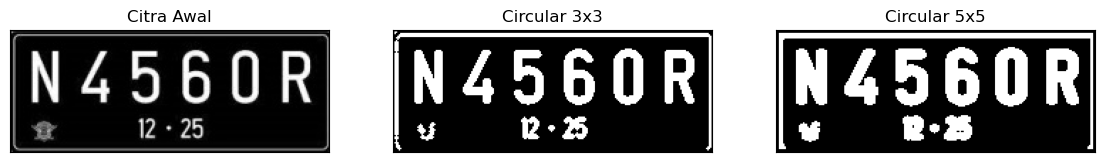

In [ ]:
def dilasi_circular(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2

    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

img_d = cv2.imread(get_image_path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

imgD_circle3 = dilasi_circular(thresh, 3)
imgD_circle5 = dilasi_circular(thresh, 5)

plt.figure(figsize=(14, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD_circle3, cmap='gray')
plt.title('Circular 3x3'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(imgD_circle5, cmap='gray')
plt.title('Circular 5x5'), plt.xticks([]), plt.yticks([])
plt.show()


### 11. Erosi Structuring Element Rectangle 3x5 dan 5x7


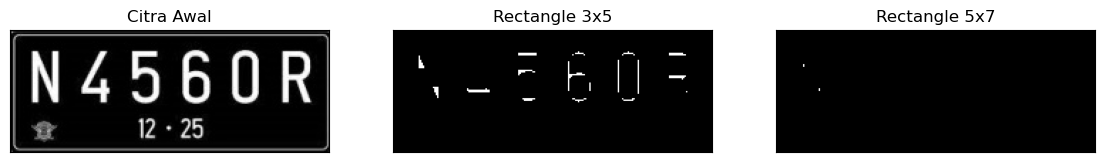

In [ ]:
def erosi_rectangle(F, p, l):
    m, n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i - constant1:i + constant1 + 1, j - constant2:j + constant2 + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

img_e = cv2.imread(get_image_path('plat nomer.jpg'), 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

imgE_rect35 = erosi_rectangle(thresh1, 5, 3)
imgE_rect57 = erosi_rectangle(thresh1, 7, 5)

plt.figure(figsize=(14, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE_rect35, cmap='gray')
plt.title('Rectangle 3x5'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(imgE_rect57, cmap='gray')
plt.title('Rectangle 5x7'), plt.xticks([]), plt.yticks([])
plt.show()


### 12. Erosi Structuring Element Line Vertikal 3 dan 5


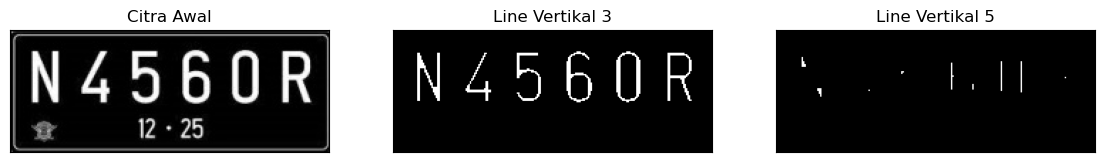

In [ ]:
def erosi_line_vertikal(F, k):
    m, n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

img_e = cv2.imread(get_image_path('plat nomer.jpg'), 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

imgE_line3 = erosi_line_vertikal(thresh1, 3)
imgE_line5 = erosi_line_vertikal(thresh1, 5)

plt.figure(figsize=(14, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE_line3, cmap='gray')
plt.title('Line Vertikal 3'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(imgE_line5, cmap='gray')
plt.title('Line Vertikal 5'), plt.xticks([]), plt.yticks([])
plt.show()


### 13. Transformasi Top-Hat


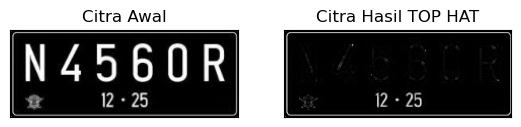

In [ ]:
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img = cv2.imread(get_image_path('plat nomer.jpg'))
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()


### 14. Transformasi Black-Hat


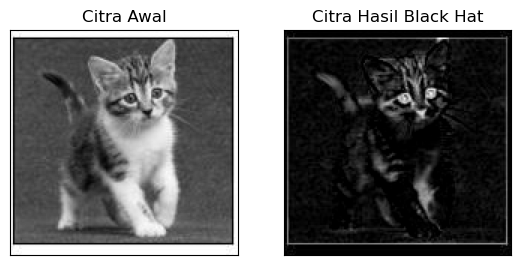

In [ ]:
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img = cv2.imread(get_image_path('kitten01.jpg'))
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()


### 15. Skeletonisasi


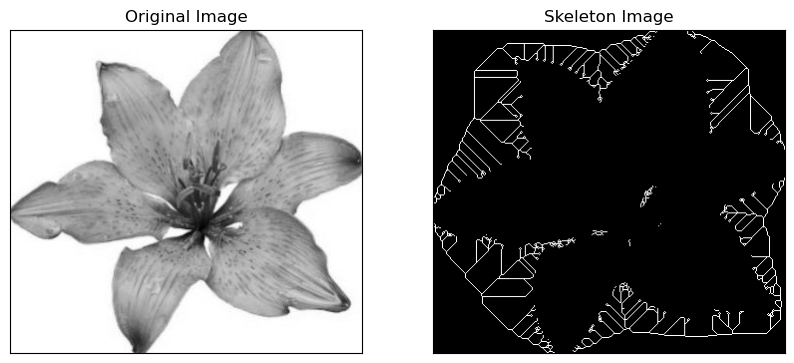

In [ ]:
img = cv2.imread(get_image_path('lily.jpg'), 0)
binary = img > filters.threshold_triangle(img)
binary_cp = binary.copy().astype(np.uint8)

skeleton = morphology.skeletonize(binary_cp)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('Skeleton Image'), plt.xticks([]), plt.yticks([])
plt.savefig('binary and bin_skeleton.png')
plt.show()


### 16. Skeletonisasi Inverse


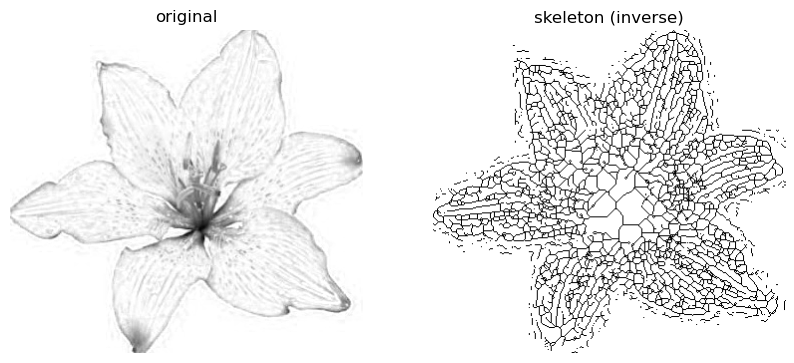

In [ ]:
img = io.imread(get_image_path('lily.jpg'))
if img.ndim == 3:
    img = img[..., 0]

binary = img < filters.threshold_triangle(img)
skeleton = morphology.skeletonize(binary)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()
plt.show()


### 17. Thinning


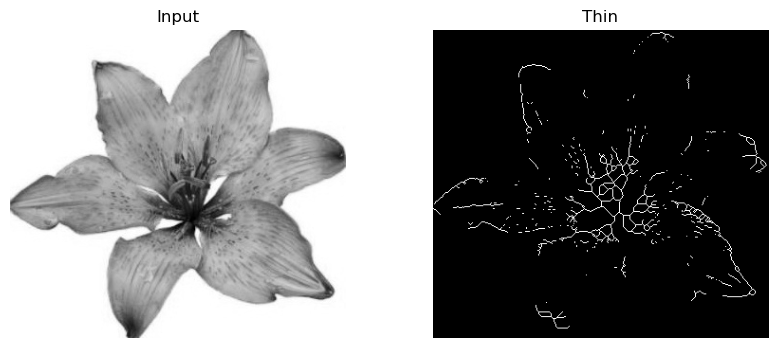

In [ ]:
image = img_as_float(color.rgb2gray(io.imread(get_image_path('lily.jpg'))))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 4))
ax0.imshow(image, cmap='gray')
ax0.set_title('Input')
ax0.set_axis_off()

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')
ax1.set_axis_off()

plt.savefig('char_out.png')
plt.show()


## E. Tugas Praktikum
Implementasi teknik morfologi pada dataset KTP () dari Modul 7 untuk meningkatkan keterbacaan teks citra KTP.


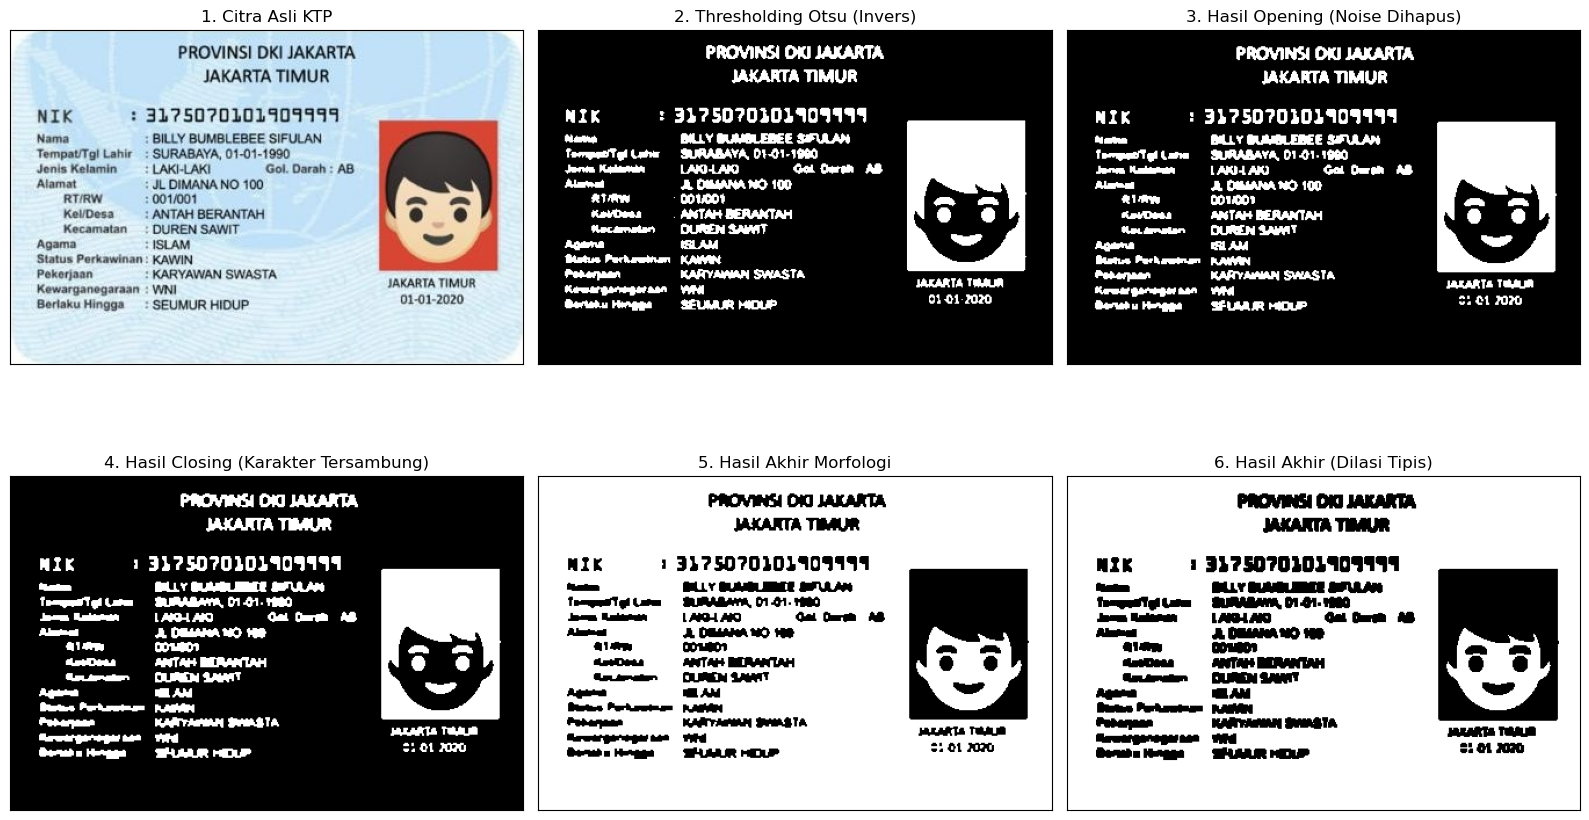

In [ ]:
img_ktp = cv2.imread(get_image_path('ktp_fulan.jpg'))
gray_ktp = cv2.cvtColor(img_ktp, cv2.COLOR_BGR2GRAY)

blurred = cv2.GaussianBlur(gray_ktp, (3, 3), 0)
_, thresh_inv = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

kernel_noise = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
opening_ktp = cv2.morphologyEx(thresh_inv, cv2.MORPH_OPEN, kernel_noise)

kernel_stroke = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
closing_ktp = cv2.morphologyEx(opening_ktp, cv2.MORPH_CLOSE, kernel_stroke)

kernel_dilate = np.ones((2, 2), np.uint8)
dilated_ktp = cv2.dilate(closing_ktp, kernel_dilate, iterations=1)

hasil_bersih = cv2.bitwise_not(closing_ktp)
hasil_tebal = cv2.bitwise_not(dilated_ktp)

plt.figure(figsize=(16, 10))

plt.subplot(231), plt.imshow(cv2.cvtColor(img_ktp, cv2.COLOR_BGR2RGB))
plt.title('1. Citra Asli KTP'), plt.xticks([]), plt.yticks([])

plt.subplot(232), plt.imshow(thresh_inv, cmap='gray')
plt.title('2. Thresholding Otsu (Invers)'), plt.xticks([]), plt.yticks([])

plt.subplot(233), plt.imshow(opening_ktp, cmap='gray')
plt.title('3. Hasil Opening (Noise Dihapus)'), plt.xticks([]), plt.yticks([])

plt.subplot(234), plt.imshow(closing_ktp, cmap='gray')
plt.title('4. Hasil Closing (Karakter Tersambung)'), plt.xticks([]), plt.yticks([])

plt.subplot(235), plt.imshow(hasil_bersih, cmap='gray')
plt.title('5. Hasil Akhir Morfologi'), plt.xticks([]), plt.yticks([])

plt.subplot(236), plt.imshow(hasil_tebal, cmap='gray')
plt.title('6. Hasil Akhir (Dilasi Tipis)'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()


### Analisis Hasil Pengolahan Morfologi pada Citra KTP:
1. **Otsu Thresholding**: Memisahkan teks dari latar belakang kartu, namun menghasilkan bintik noise akibat pola/watermark pada kartu KTP dan garis huruf yang terputus.
2. **Opening (Erosi dilanjutkan Dilasi)**: Menghapus komponen noise berukuran kecil pada background tanpa mengubah struktur utama teks.
3. **Closing (Dilasi dilanjutkan Erosi)**: Menutup celah kecil dan menyambung segmen stroke huruf yang patah atau berlubang.
4. **Hasil Akhir**: Teks KTP (NIK, Nama, Alamat, dll.) memiliki kontras tajam, bebas derau latar belakang, dan karakter huruf utuh sehingga siap dibaca oleh sistem OCR maupun manusia.
